In [1]:
from google.colab import files

uploaded = files.upload()


Saving dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx to dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_name = next(iter(uploaded))

excel = pd.ExcelFile(file_name)
print("Листы:", excel.sheet_names)

users = pd.read_excel(file_name, sheet_name="Пользователи")
payments = pd.read_excel(file_name, sheet_name="Платежи")

print("Пользователей:", len(users))
print("Платежей:", len(payments))

display(users.head())
display(payments.head())


Листы: ['Пользователи', 'Платежи']
Пользователей: 1504
Платежей: 2661


,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


In [3]:

print("ПРОПУСКИ В ПОЛЬЗОВАТЕЛЯХ")
print(users.isna().sum())

print("\nПРОПУСКИ В ПЛАТЕЖАХ")
print(payments.isna().sum())

print("\nДУБЛИКАТЫ")
print("Повторяющиеся user_id:",
      users["user_id"].duplicated().sum())

print("Повторяющиеся payment_id:",
      payments["payment_id"].duplicated().sum())

print("\nГРУППЫ ПОЛЬЗОВАТЕЛЕЙ")
print(users["group"].value_counts(dropna=False))

print("\nГРУППЫ ПЛАТЕЖЕЙ")
print(payments["group"].value_counts(dropna=False))

unknown = payments[
    ~payments["user_id"].isin(users["user_id"])
]

print("\nПлатежи с неизвестными user_id:")
display(unknown)


ПРОПУСКИ В ПОЛЬЗОВАТЕЛЯХ
user_id        0
group          1
age            0
city           1
device_type    0
dtype: int64

ПРОПУСКИ В ПЛАТЕЖАХ
payment_id            0
user_id               1
group                 0
step1_opened          0
step2_entered       405
step3_confirmed     942
step4_success      1139
dtype: int64

ДУБЛИКАТЫ
Повторяющиеся user_id: 0
Повторяющиеся payment_id: 0

ГРУППЫ ПОЛЬЗОВАТЕЛЕЙ
group
A      752
B      751
NaN      1
Name: count, dtype: int64

ГРУППЫ ПЛАТЕЖЕЙ
group
B    1352
A    1309
Name: count, dtype: int64

Платежи с неизвестными user_id:


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2660,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT


In [4]:

check = payments.merge(
    users[["user_id", "group"]],
    on="user_id",
    how="left",
    suffixes=("_payment", "_user")
)

mismatch = check[
    check["group_payment"] != check["group_user"]
]

display(mismatch)
print("Несовпадений:", len(mismatch))


,payment_id,user_id,group_payment,step1_opened,step2_entered,step3_confirmed,step4_success,group_user
2659,99002,1010.0,B,2024-04-08 14:20:00,2024-04-08 14:23:00,2024-04-08 14:28:00,2024-04-08 14:29:00,A
2660,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT,NaN


Несовпадений: 2


In [5]:

df = check[
    (check["group_payment"] == check["group_user"])
    & check["group_user"].isin(["A", "B"])
].copy()

steps = [
    "step1_opened",
    "step2_entered",
    "step3_confirmed",
    "step4_success"
]

funnel = df.groupby("group_user")[steps].count()

conversion = funnel.div(
    funnel["step1_opened"], axis=0
) * 100

print("Платежей после очистки:", len(df))
print("\nКоличество прохождений этапов:")
display(funnel)

print("\nКонверсия от открытия формы, %:")
display(conversion.round(2))


Платежей после очистки: 2659

Количество прохождений этапов:


,step1_opened,step2_entered,step3_confirmed,step4_success
group_user,,,,
A,1308,1061,758,651
B,1351,1194,960,870



Конверсия от открытия формы, %:


,step1_opened,step2_entered,step3_confirmed,step4_success
group_user,,,,
A,100.0,81.12,57.95,49.77
B,100.0,88.38,71.06,64.40


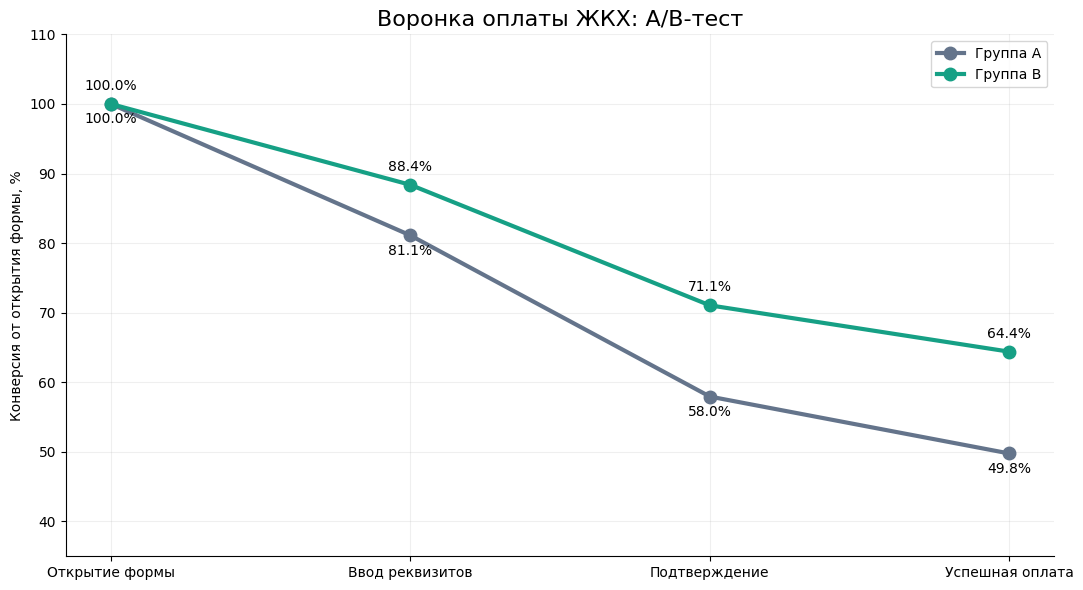

In [6]:

import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "DejaVu Sans"

labels = [
    "Открытие формы",
    "Ввод реквизитов",
    "Подтверждение",
    "Успешная оплата"
]

fig, ax = plt.subplots(figsize=(11, 6))

for group, color in [("A", "#64748b"), ("B", "#16a085")]:
    values = conversion.loc[group, steps].values

    ax.plot(
        labels, values,
        marker="o",
        markersize=9,
        linewidth=3,
        label=f"Группа {group}",
        color=color
    )

    for i, value in enumerate(values):
        offset = -14 if group == "A" else 10
        ax.annotate(
            f"{value:.1f}%",
            (i, value),
            xytext=(0, offset),
            textcoords="offset points",
            ha="center",
            fontsize=10
        )

ax.set_title("Воронка оплаты ЖКХ: A/B-тест", fontsize=16)
ax.set_ylabel("Конверсия от открытия формы, %")
ax.set_ylim(35, 110)
ax.grid(alpha=0.2)
ax.legend()
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("funnel.png", dpi=200, bbox_inches="tight")
plt.show()


,Открытие → Ввод,Ввод → Подтверждение,Подтверждение → Оплата
A,81.12,71.44,85.88
B,88.38,80.40,90.62


Прирост конверсии по переходам, п.п.:


,0
Открытие → Ввод,7.26
Ввод → Подтверждение,8.96
Подтверждение → Оплата,4.74


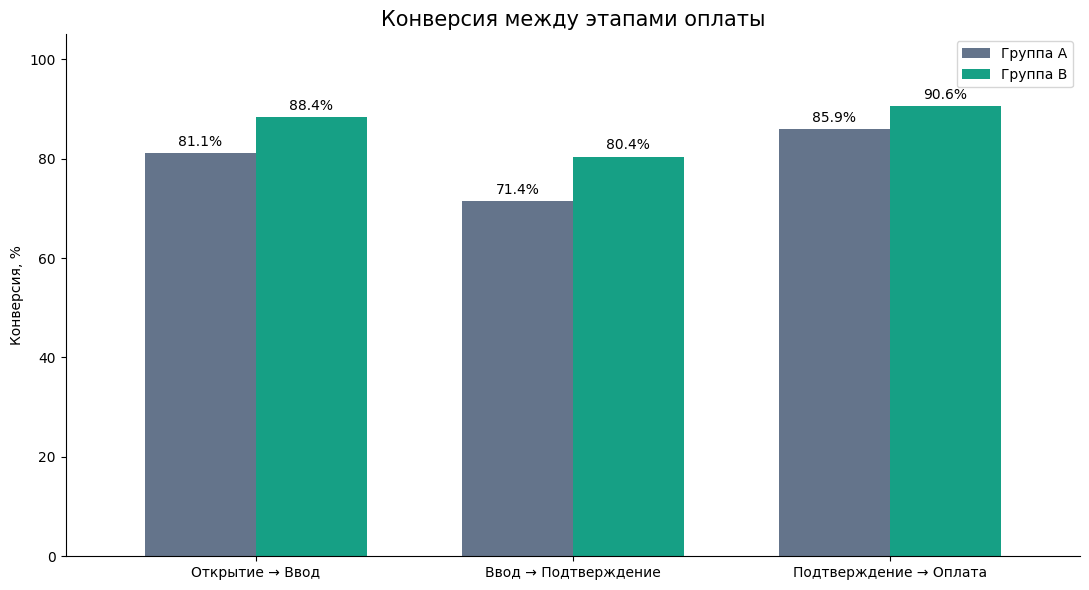

In [7]:

step_conversion = pd.DataFrame(index=["A", "B"])

step_conversion["Открытие → Ввод"] = (
    funnel["step2_entered"] / funnel["step1_opened"] * 100
)

step_conversion["Ввод → Подтверждение"] = (
    funnel["step3_confirmed"] / funnel["step2_entered"] * 100
)

step_conversion["Подтверждение → Оплата"] = (
    funnel["step4_success"] / funnel["step3_confirmed"] * 100
)

display(step_conversion.round(2))

difference = step_conversion.loc["B"] - step_conversion.loc["A"]

print("Прирост конверсии по переходам, п.п.:")
display(difference.round(2))

ax = step_conversion.T.plot(
    kind="bar",
    figsize=(11, 6),
    color=["#64748b", "#16a085"],
    width=0.7
)

ax.set_title("Конверсия между этапами оплаты", fontsize=15)
ax.set_ylabel("Конверсия, %")
ax.set_xlabel("")
ax.set_ylim(0, 105)
ax.legend(["Группа A", "Группа B"])
ax.tick_params(axis="x", rotation=0)
ax.spines[["top", "right"]].set_visible(False)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.savefig("step_conversion.png", dpi=200, bbox_inches="tight")
plt.show()


In [8]:

from statsmodels.stats.proportion import proportions_ztest
import numpy as np

df["success"] = df["step4_success"].notna().astype(int)

user_level = (
    df.groupby(["group_user", "user_id"])["success"]
    .max()
    .reset_index()
)

result = user_level.groupby("group_user")["success"].agg(
    successes="sum",
    total="count",
    conversion="mean"
)

display(result)

successes = result.loc[["A", "B"], "successes"].values
totals = result.loc[["A", "B"], "total"].values

z_stat, p_value = proportions_ztest(successes, totals)

p_a = result.loc["A", "conversion"]
p_b = result.loc["B", "conversion"]

diff = p_b - p_a

se = np.sqrt(
    p_a * (1 - p_a) / totals[0]
    + p_b * (1 - p_b) / totals[1]
)

ci_low = diff - 1.96 * se
ci_high = diff + 1.96 * se

print(f"Конверсия A: {p_a:.2%}")
print(f"Конверсия B: {p_b:.2%}")
print(f"Прирост: {diff * 100:.2f} п.п.")
print(f"Относительный прирост: {(p_b / p_a - 1) * 100:.2f}%")
print(f"Z-статистика: {z_stat:.4f}")
print(f"p-value: {p_value:.12g}")
print(f"95% ДИ: [{ci_low * 100:.2f}; {ci_high * 100:.2f}] п.п.")

if p_value < 0.05:
    print("Различие статистически значимо")
else:
    print("Статистически значимого различия нет")


,successes,total,conversion
group_user,,,
A,493,751,0.656458
B,603,750,0.804000


Конверсия A: 65.65%
Конверсия B: 80.40%
Прирост: 14.75 п.п.
Относительный прирост: 22.48%
Z-статистика: -6.4391
p-value: 1.20201734865e-10
95% ДИ: [10.33; 19.18] п.п.
Различие статистически значимо


In [9]:

import statsmodels.api as sm

attempts = df.copy()

attempts["success"] = attempts["step4_success"].notna().astype(int)
attempts["is_B"] = (attempts["group_user"] == "B").astype(int)

X = sm.add_constant(attempts["is_B"])

model = sm.GLM(
    attempts["success"],
    X,
    family=sm.families.Binomial()
)

fit = model.fit(
    cov_type="cluster",
    cov_kwds={"groups": attempts["user_id"]}
)

print(fit.summary())

cr = attempts.groupby("group_user")["success"].mean()

print(f"\nКонверсия A: {cr['A']:.2%}")
print(f"Конверсия B: {cr['B']:.2%}")
print(f"Разница: {(cr['B'] - cr['A']) * 100:.2f} п.п.")
print(f"p-value: {fit.pvalues['is_B']:.12g}")


                 Generalized Linear Model Regression Results                  
Dep. Variable:                success   No. Observations:                 2659
Model:                            GLM   Df Residuals:                     2657
Model Family:                Binomial   Df Model:                            1
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -1786.3
Date:                Sun, 08 Nov 2026   Deviance:                       3572.5
Time:                        08:52:23   Pearson chi2:                 2.66e+03
No. Iterations:                     4   Pseudo R-squ. (CS):            0.02168
Covariance Type:              cluster                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0092      0.054     -0.169      0.8

,device_type,group_user,sum,count,mean,conversion_pct
0,android,A,349,714,0.49,48.88
1,android,B,425,666,0.64,63.81
2,ios,A,302,594,0.51,50.84
3,ios,B,445,685,0.65,64.96


group_user,A,B,"Разница, п.п."
device_type,,,
android,48.88,63.81,14.93
ios,50.84,64.96,14.12


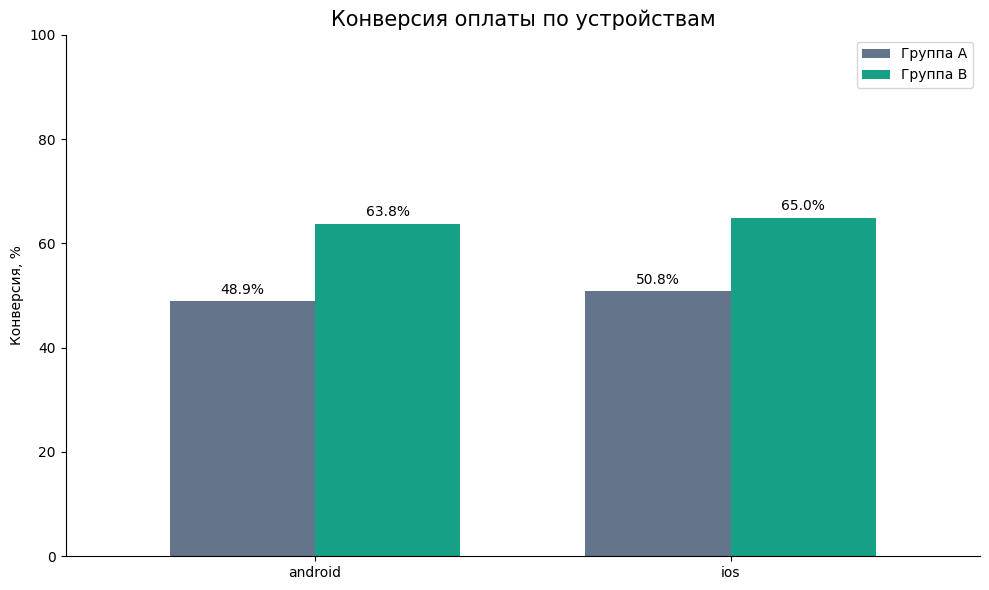

In [10]:

segment_df = df.merge(
    users[["user_id", "device_type", "age", "city"]],
    on="user_id",
    how="left"
)

device_stats = (
    segment_df.groupby(["device_type", "group_user"])["success"]
    .agg(["sum", "count", "mean"])
    .reset_index()
)

device_stats["conversion_pct"] = device_stats["mean"] * 100

display(device_stats.round(2))

device_pivot = device_stats.pivot(
    index="device_type",
    columns="group_user",
    values="conversion_pct"
)

device_pivot["Разница, п.п."] = device_pivot["B"] - device_pivot["A"]

display(device_pivot.round(2))

ax = device_pivot[["A", "B"]].plot(
    kind="bar",
    figsize=(10, 6),
    color=["#64748b", "#16a085"],
    width=0.7
)

ax.set_title("Конверсия оплаты по устройствам", fontsize=15)
ax.set_ylabel("Конверсия, %")
ax.set_xlabel("")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(["Группа A", "Группа B"])
ax.spines[["top", "right"]].set_visible(False)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.savefig("device_conversion.png", dpi=200, bbox_inches="tight")
plt.show()


In [11]:

import statsmodels.formula.api as smf
import statsmodels.api as sm

segment_df["is_B"] = (
    segment_df["group_user"] == "B"
).astype(int)

interaction_model = smf.glm(
    "success ~ is_B * C(device_type)",
    data=segment_df,
    family=sm.families.Binomial()
).fit(
    cov_type="cluster",
    cov_kwds={"groups": segment_df["user_id"]}
)

print(interaction_model.summary())

interaction_terms = [
    name for name in interaction_model.params.index
    if "is_B:C(device_type)" in name
]

for term in interaction_terms:
    print(f"{term}: p-value = {interaction_model.pvalues[term]:.6f}")


                 Generalized Linear Model Regression Results                  
Dep. Variable:                success   No. Observations:                 2659
Model:                            GLM   Df Residuals:                     2655
Model Family:                Binomial   Df Model:                            3
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -1785.9
Date:                Sun, 08 Nov 2026   Deviance:                       3571.8
Time:                        08:54:04   Pearson chi2:                 2.66e+03
No. Iterations:                     4   Pseudo R-squ. (CS):            0.02193
Covariance Type:              cluster                                         
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

group_user,A,B,"Разница, п.п."
age_group,,,
До 25,55.29,67.81,12.51
26–35,47.60,65.19,17.58
36–45,50.00,61.17,11.17
46+,47.62,65.52,17.90


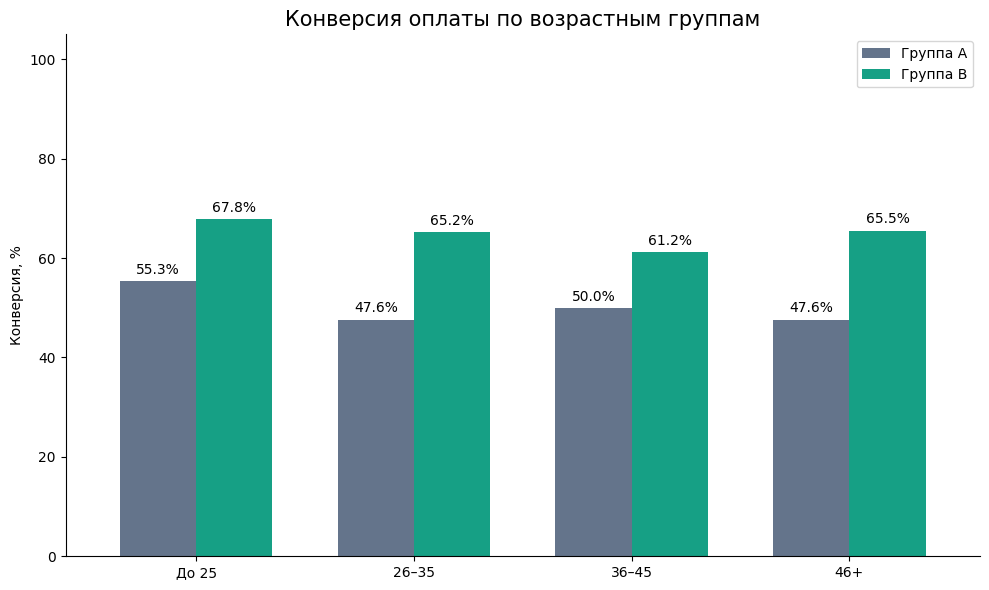

In [12]:

segment_df["age_group"] = pd.cut(
    segment_df["age"],
    bins=[0, 25, 35, 45, float("inf")],
    labels=["До 25", "26–35", "36–45", "46+"],
    include_lowest=True
)

age_stats = (
    segment_df.groupby(
        ["age_group", "group_user"],
        observed=True
    )["success"]
    .agg(["sum", "count", "mean"])
    .reset_index()
)

age_stats["conversion_pct"] = age_stats["mean"] * 100

age_pivot = age_stats.pivot(
    index="age_group",
    columns="group_user",
    values="conversion_pct"
)

age_pivot["Разница, п.п."] = (
    age_pivot["B"] - age_pivot["A"]
)

display(age_pivot.round(2))

ax = age_pivot[["A", "B"]].plot(
    kind="bar",
    figsize=(10, 6),
    color=["#64748b", "#16a085"],
    width=0.7
)

ax.set_title("Конверсия оплаты по возрастным группам", fontsize=15)
ax.set_ylabel("Конверсия, %")
ax.set_xlabel("")
ax.set_ylim(0, 105)
ax.tick_params(axis="x", rotation=0)
ax.legend(["Группа A", "Группа B"])
ax.spines[["top", "right"]].set_visible(False)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.savefig("age_conversion.png", dpi=200, bbox_inches="tight")
plt.show()


In [13]:

import statsmodels.formula.api as smf
import statsmodels.api as sm
import numpy as np

age_df = segment_df.dropna(subset=["age_group"]).copy()

model_age = smf.glm(
    "success ~ is_B * C(age_group)",
    data=age_df,
    family=sm.families.Binomial()
).fit(
    cov_type="cluster",
    cov_kwds={"groups": age_df["user_id"]}
)

terms = [
    name for name in model_age.params.index
    if "is_B:C(age_group)" in name
]

R = np.zeros((len(terms), len(model_age.params)))

for i, term in enumerate(terms):
    R[i, model_age.params.index.get_loc(term)] = 1

test = model_age.wald_test(R, scalar=True)

print(model_age.summary())
print(f"\nОбщий p-value взаимодействия: {float(test.pvalue):.6f}")

if test.pvalue < 0.05:
    print("Эффект статистически значимо различается по возрасту")
else:
    print("Значимых различий эффекта между возрастными группами не обнаружено")


                 Generalized Linear Model Regression Results                  
Dep. Variable:                success   No. Observations:                 2659
Model:                            GLM   Df Residuals:                     2651
Model Family:                Binomial   Df Model:                            7
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -1782.2
Date:                Sun, 08 Nov 2026   Deviance:                       3564.4
Time:                        08:55:41   Pearson chi2:                 2.66e+03
No. Iterations:                     4   Pseudo R-squ. (CS):            0.02468
Covariance Type:              cluster                                         
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

In [14]:

dates = df.copy()

for step in steps:
    dates[step] = pd.to_datetime(dates[step], errors="coerce")

start = pd.Timestamp("2024-04-01")
end = pd.Timestamp("2024-05-01")

outside = dates[
    (dates["step1_opened"] < start) |
    (dates["step1_opened"] >= end)
]

invalid_order = pd.Series(False, index=dates.index)

for previous, current in zip(steps[:-1], steps[1:]):
    invalid_order |= (
        dates[current].notna() &
        (
            dates[previous].isna() |
            (dates[current] < dates[previous])
        )
    )

invalid = dates[invalid_order]

duration = (
    dates["step4_success"] -
    dates["step1_opened"]
).dt.total_seconds() / 60

print("Платежи вне периода теста:", len(outside))
print("Нарушения порядка этапов:", len(invalid))

print("\nДлительность успешных платежей, минуты:")
display(duration.dropna().describe(
    percentiles=[0.5, 0.9, 0.95, 0.99]
))

print("\nПлатежи с нарушениями:")
display(invalid)

print("\nПлатежи вне периода:")
display(outside)


Платежи вне периода теста: 0
Нарушения порядка этапов: 0

Длительность успешных платежей, минуты:


,0
count,1521.000000
mean,12.381986
std,2.808711
min,5.000000
50%,12.000000
90%,16.000000
95%,17.000000
99%,20.000000
max,24.000000



Платежи с нарушениями:


,payment_id,user_id,group_payment,step1_opened,step2_entered,step3_confirmed,step4_success,group_user,success



Платежи вне периода:


,payment_id,user_id,group_payment,step1_opened,step2_entered,step3_confirmed,step4_success,group_user,success


,count,mean,median,std
group_user,,,,
A,651,12.42,12.0,2.67
B,870,12.35,12.0,2.91


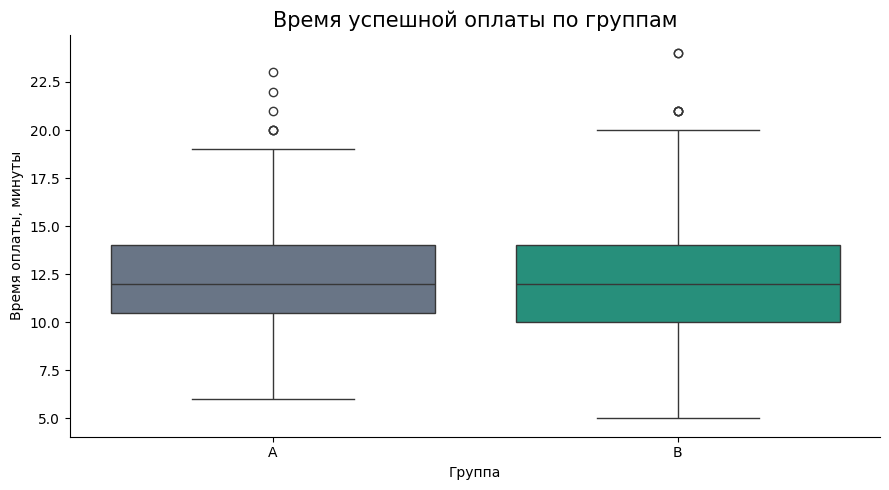

In [15]:

time_df = dates[dates["step4_success"].notna()].copy()

time_df["duration_min"] = (
    time_df["step4_success"] - time_df["step1_opened"]
).dt.total_seconds() / 60

time_stats = time_df.groupby("group_user")["duration_min"].agg(
    ["count", "mean", "median", "std"]
)

display(time_stats.round(2))

fig, ax = plt.subplots(figsize=(9, 5))

sns.boxplot(
    data=time_df,
    x="group_user",
    y="duration_min",
    order=["A", "B"],
    palette=["#64748b", "#16a085"],
    hue="group_user",
    legend=False,
    ax=ax
)

ax.set_title("Время успешной оплаты по группам", fontsize=15)
ax.set_xlabel("Группа")
ax.set_ylabel("Время оплаты, минуты")
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("payment_duration.png", dpi=200, bbox_inches="tight")
plt.show()
